In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("healthcare_disease_prediction_2000.csv")
df.head()

,Patient_ID,Age,Gender,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Cholesterol,Glucose_Level,Smoking,Alcohol_Intake,Physical_Activity,Family_History,Heart_Disease,Diabetes,Stroke
0,1,69,Male,34.1,127,71,184,154,1,1,0,0,0,1,0
1,2,32,Male,25.0,148,69,177,136,1,1,1,0,0,0,0
2,3,78,Male,25.2,98,93,252,110,0,0,0,0,0,0,0
3,4,38,Male,9.6,162,102,274,87,1,0,1,0,0,0,0
4,5,41,Female,29.0,161,69,251,127,0,1,1,0,0,0,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Patient_ID                2000 non-null   int64  
 1   Age                       2000 non-null   int64  
 2   Gender                    2000 non-null   object 
 3   BMI                       2000 non-null   float64
 4   Blood_Pressure_Systolic   2000 non-null   int64  
 5   Blood_Pressure_Diastolic  2000 non-null   int64  
 6   Cholesterol               2000 non-null   int64  
 7   Glucose_Level             2000 non-null   int64  
 8   Smoking                   2000 non-null   int64  
 9   Alcohol_Intake            2000 non-null   int64  
 10  Physical_Activity         2000 non-null   int64  
 11  Family_History            2000 non-null   int64  
 12  Heart_Disease             2000 non-null   int64  
 13  Diabetes                  2000 non-null   int64  
 14  Stroke  

In [4]:
df.isnull().sum()

Patient_ID                  0
Age                         0
Gender                      0
BMI                         0
Blood_Pressure_Systolic     0
Blood_Pressure_Diastolic    0
Cholesterol                 0
Glucose_Level               0
Smoking                     0
Alcohol_Intake              0
Physical_Activity           0
Family_History              0
Heart_Disease               0
Diabetes                    0
Stroke                      0
dtype: int64

In [5]:
df.describe

<bound method NDFrame.describe of       Patient_ID  Age  Gender   BMI  Blood_Pressure_Systolic  \
0              1   69    Male  34.1                      127   
1              2   32    Male  25.0                      148   
2              3   78    Male  25.2                       98   
3              4   38    Male   9.6                      162   
4              5   41  Female  29.0                      161   
...          ...  ...     ...   ...                      ...   
1995        1996   19    Male  28.0                      114   
1996        1997   46  Female  35.2                       92   
1997        1998   69    Male  30.1                       98   
1998        1999   44    Male  23.2                      175   
1999        2000   67    Male  25.8                      176   

      Blood_Pressure_Diastolic  Cholesterol  Glucose_Level  Smoking  \
0                           71          184            154        1   
1                           69          177            

# EDA : Exploratory Data Analysis

Text(0.5, 1.0, 'Heart disease is there or not')

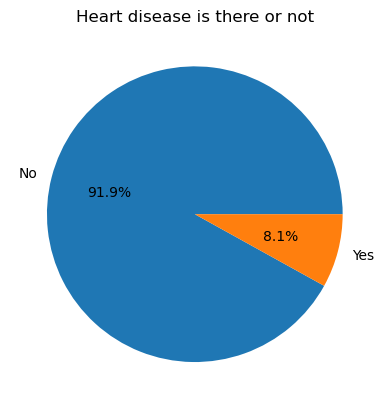

In [6]:
class_count = df["Heart_Disease"].value_counts()
plt.pie(class_count,labels = ["No","Yes"],autopct = "%1.1f%%")
plt.title("Heart disease is there or not")

Text(0.5, 1.0, 'Diabetes is there or not')

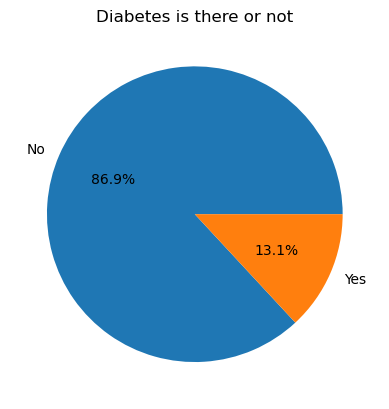

In [7]:
class_count = df["Diabetes"].value_counts()
plt.pie(class_count,labels = ["No","Yes"],autopct = "%1.1f%%")
plt.title("Diabetes is there or not")

Text(0.5, 1.0, 'stroke will happen or not')

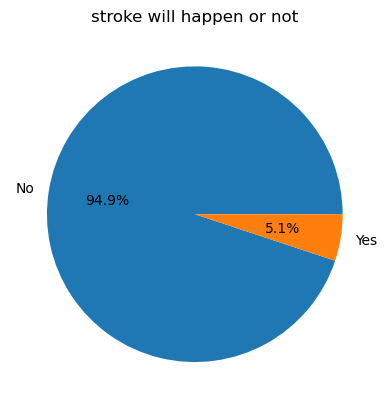

In [8]:
class_count = df["Stroke"].value_counts()
plt.pie(class_count,labels = ["No","Yes"],autopct = "%1.1f%%")
plt.title("stroke will happen or not")

<Axes: xlabel='Gender', ylabel='count'>

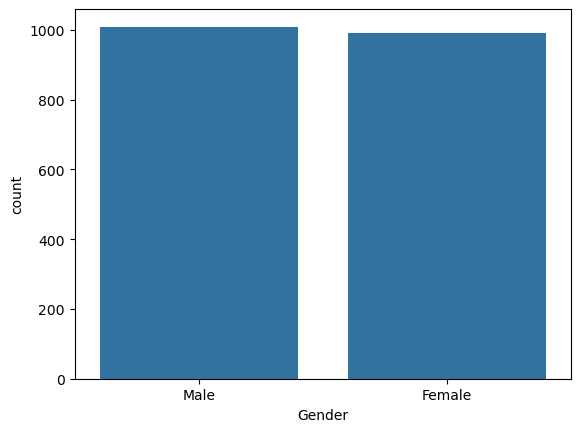

In [9]:
# how many males and females are there
gender_counts = df["Gender"].value_counts()
sns.barplot(gender_counts)

<Axes: xlabel='Cholesterol', ylabel='Count'>

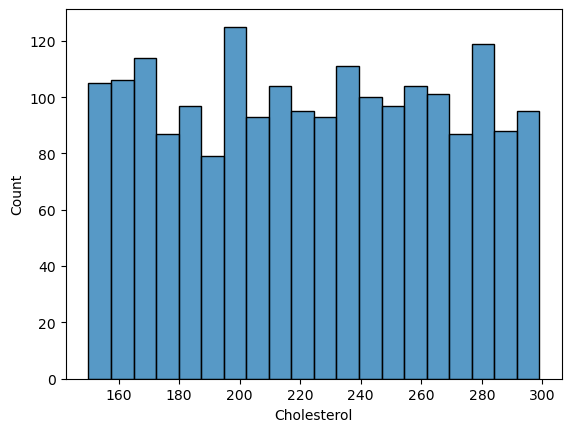

In [10]:
# How many  number of person ranges between different cholesterol value:
sns.histplot(
    data = df,
    x = "Cholesterol",
    bins = 20
)
    

<Axes: xlabel='Glucose_Level', ylabel='Count'>

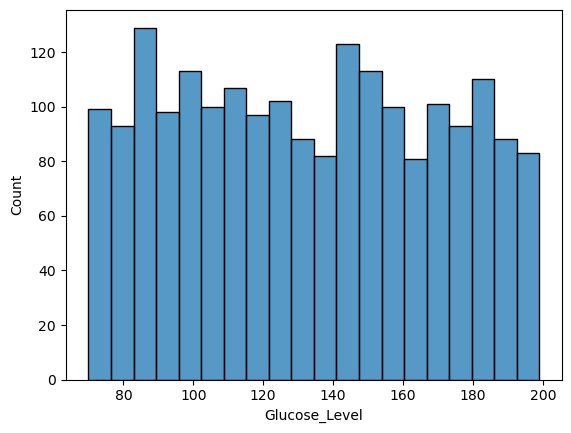

In [11]:
# How many number of person ranges between different glucose levels:
sns.histplot(
    data = df,
    x = "Glucose_Level",
    bins = 20
)

<Axes: xlabel='Blood_Pressure_Diastolic', ylabel='Count'>

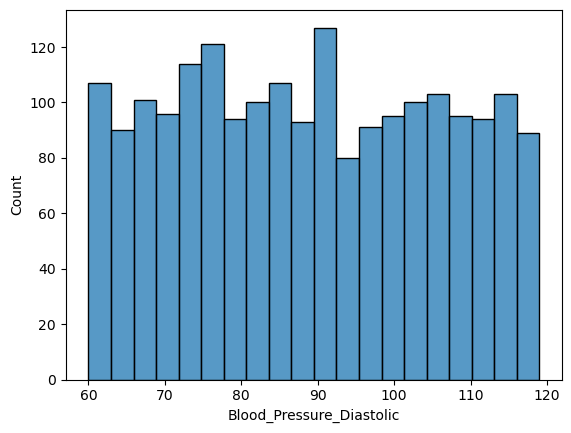

In [12]:
# How many number of person ranges between blood pressure diastolic
sns.histplot(
    data = df,
    x = "Blood_Pressure_Diastolic",
    bins = 20
)

<Axes: xlabel='Blood_Pressure_Systolic', ylabel='Count'>

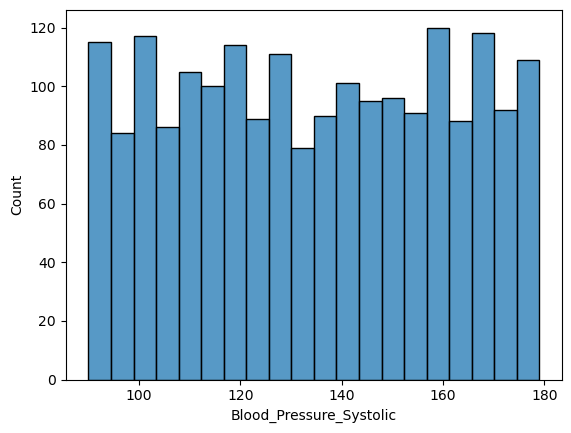

In [13]:
# how many number of person ranges between Blood Pressure systolic
sns.histplot(
    data = df,
    x = "Blood_Pressure_Systolic",
    bins = 20
)

<Axes: xlabel='Heart_Disease', ylabel='Cholesterol'>

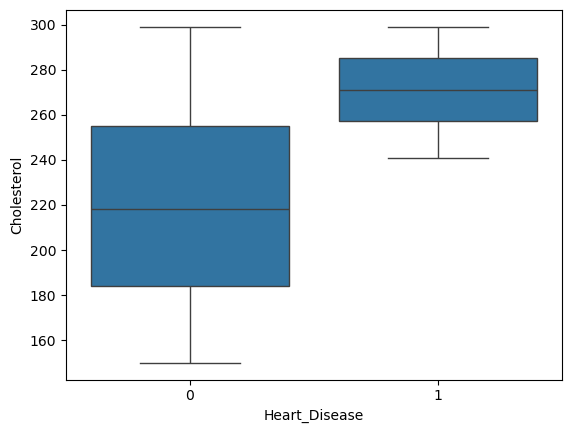

In [14]:
# outlier = box plots
sns.boxplot(
    data = df,
    x = "Heart_Disease",
    y = "Cholesterol"
)

<Axes: xlabel='Diabetes', ylabel='Glucose_Level'>

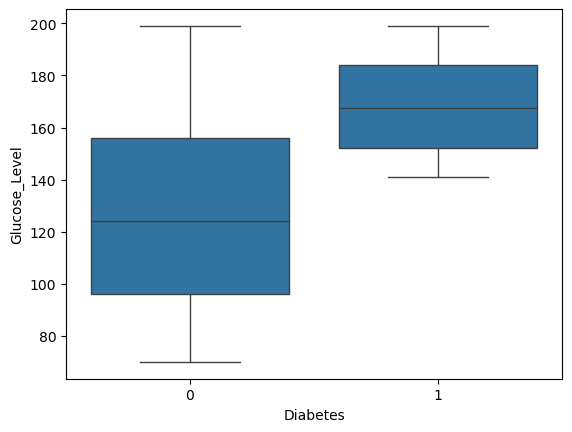

In [15]:
sns.boxplot(
    data = df,
    x = "Diabetes",
    y = "Glucose_Level"
)

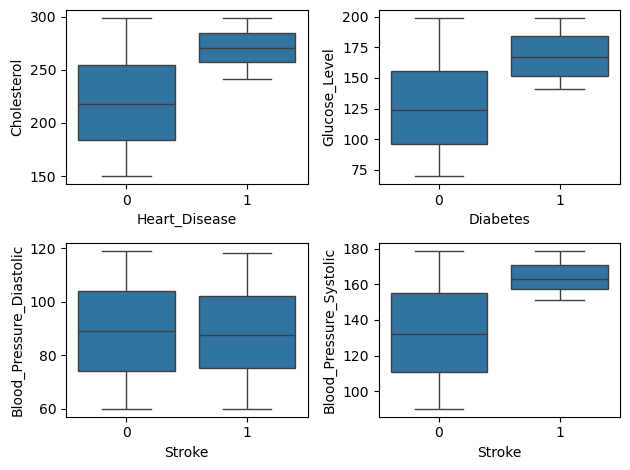

In [16]:
# outlier detection:
fig,axes = plt.subplots(2,2)
sns.boxplot(ax = axes[0,0],data = df ,x = "Heart_Disease", y = "Cholesterol")
sns.boxplot(ax = axes[0,1] ,data = df,x = "Diabetes" , y = "Glucose_Level")
sns.boxplot(ax = axes[1,0], data = df,x = "Stroke", y ="Blood_Pressure_Diastolic")
sns.boxplot(ax = axes[1,1], data = df,x = "Stroke",y = "Blood_Pressure_Systolic")
plt.tight_layout()

In [17]:
df = df.drop(columns = ["Patient_ID"])

# Encoding

In [18]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df["Gender"] = le.fit_transform(df["Gender"])
df.head()


,Age,Gender,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Cholesterol,Glucose_Level,Smoking,Alcohol_Intake,Physical_Activity,Family_History,Heart_Disease,Diabetes,Stroke
0,69,1,34.1,127,71,184,154,1,1,0,0,0,1,0
1,32,1,25.0,148,69,177,136,1,1,1,0,0,0,0
2,78,1,25.2,98,93,252,110,0,0,0,0,0,0,0
3,38,1,9.6,162,102,274,87,1,0,1,0,0,0,0
4,41,0,29.0,161,69,251,127,0,1,1,0,0,0,0


# Correlation Heatmap :

In [19]:
nums_cols = df.select_dtypes(include = "number")
corr_matrix = nums_cols.corr()

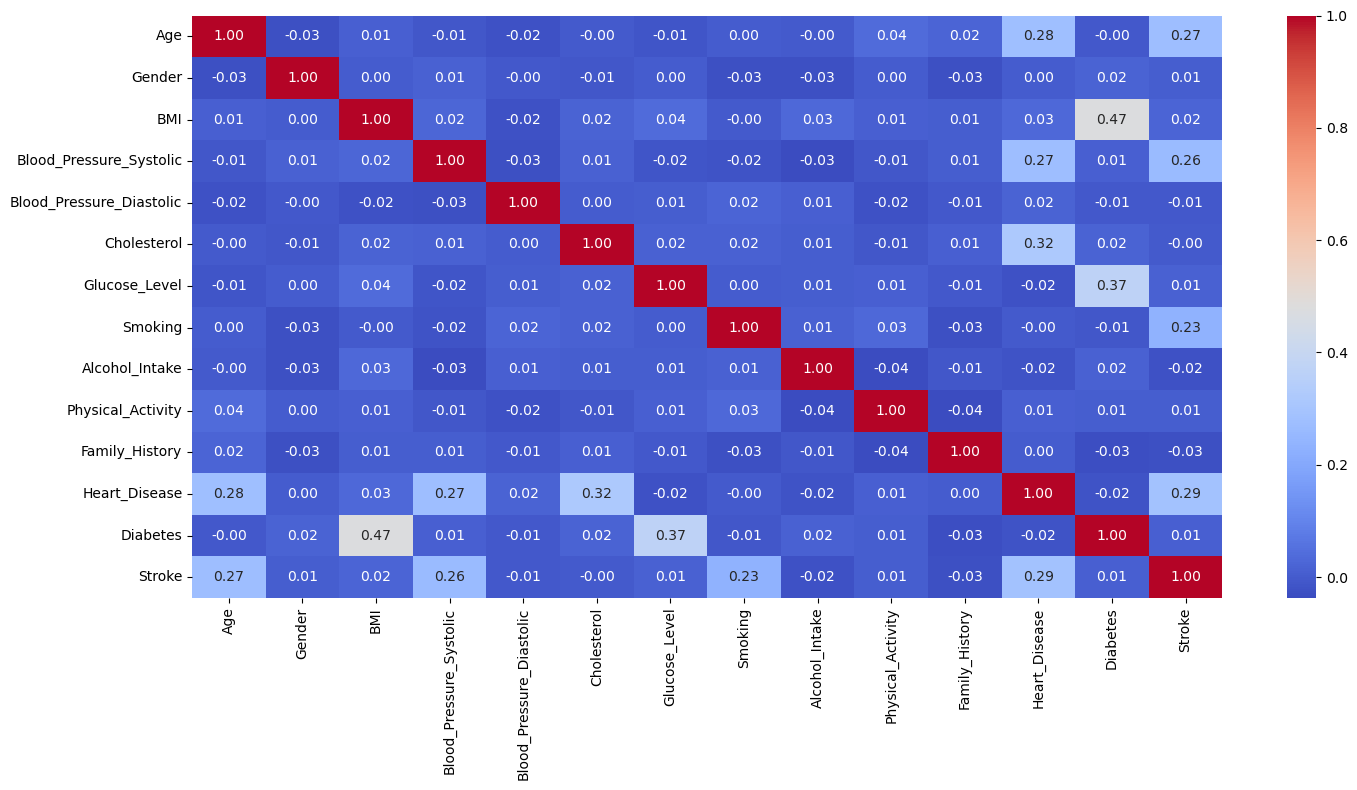

In [20]:
corr_matrix
plt.figure(figsize = (15,8))
sns.heatmap(
    corr_matrix,
    annot = True,
    fmt = ".2f",
    cmap = "coolwarm"
)
plt.tight_layout()

# Feature Engineering :

In [21]:
# new features such as BMI_Age and Gluose_BMI
df["BMI_Age"] = df["BMI"]* df["Age"]
df["Glucose_BMI"] = df["Glucose_Level"]*df["BMI"]
# new features such as Pulse_Pressure and Mean_Arterial_Pressure
df["Pulse_Pressure"] = df["Blood_Pressure_Systolic"]- df["Blood_Pressure_Diastolic"]
df["Mean_Arterial_Pressure"] = (df["Blood_Pressure_Diastolic"]+ df["Blood_Pressure_Systolic"]-df["Blood_Pressure_Diastolic"])/3
# Risk score feature creation:
df["Risk_Score"] = (df["Smoking"]+df["Diabetes"]+df["Heart_Disease"]+df["Family_History"])

In [22]:
df.head(10)

,Age,Gender,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Cholesterol,Glucose_Level,Smoking,Alcohol_Intake,Physical_Activity,Family_History,Heart_Disease,Diabetes,Stroke,BMI_Age,Glucose_BMI,Pulse_Pressure,Mean_Arterial_Pressure,Risk_Score
0,69,1,34.1,127,71,184,154,1,1,0,0,0,1,0,2352.9,5251.4,56,42.333333,2
1,32,1,25.0,148,69,177,136,1,1,1,0,0,0,0,800.0,3400.0,79,49.333333,1
2,78,1,25.2,98,93,252,110,0,0,0,0,0,0,0,1965.6,2772.0,5,32.666667,0
3,38,1,9.6,162,102,274,87,1,0,1,0,0,0,0,364.8,835.2,60,54.000000,1
4,41,0,29.0,161,69,251,127,0,1,1,0,0,0,0,1189.0,3683.0,92,53.666667,0
5,20,0,20.4,140,89,286,129,1,1,1,0,0,0,0,408.0,2631.6,51,46.666667,1
6,39,1,24.2,124,81,292,157,1,1,1,0,0,0,0,943.8,3799.4,43,41.333333,1
7,70,0,21.9,171,65,170,96,1,0,0,1,0,0,1,1533.0,2102.4,106,57.000000,2
8,19,1,25.2,94,109,201,137,1,1,1,0,0,0,0,478.8,3452.4,-15,31.333333,1
9,47,1,29.2,103,61,246,91,1,0,1,1,0,0,0,1372.4,2657.2,42,34.333333,2


# Train-Test-Split + Feature Scaling

In [23]:
X = df.drop(columns = ["Heart_Disease","Diabetes","Stroke"])
Y = df[["Heart_Disease","Diabetes","Stroke"]]

In [24]:
X.head()

,Age,Gender,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Cholesterol,Glucose_Level,Smoking,Alcohol_Intake,Physical_Activity,Family_History,BMI_Age,Glucose_BMI,Pulse_Pressure,Mean_Arterial_Pressure,Risk_Score
0,69,1,34.1,127,71,184,154,1,1,0,0,2352.9,5251.4,56,42.333333,2
1,32,1,25.0,148,69,177,136,1,1,1,0,800.0,3400.0,79,49.333333,1
2,78,1,25.2,98,93,252,110,0,0,0,0,1965.6,2772.0,5,32.666667,0
3,38,1,9.6,162,102,274,87,1,0,1,0,364.8,835.2,60,54.000000,1
4,41,0,29.0,161,69,251,127,0,1,1,0,1189.0,3683.0,92,53.666667,0


In [25]:
Y.head(10)

,Heart_Disease,Diabetes,Stroke
0,0,1,0
1,0,0,0
2,0,0,0
3,0,0,0
4,0,0,0
5,0,0,0
6,0,0,0
7,0,0,1
8,0,0,0
9,0,0,0


In [26]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42)

In [27]:
X_train.head()

,Age,Gender,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Cholesterol,Glucose_Level,Smoking,Alcohol_Intake,Physical_Activity,Family_History,BMI_Age,Glucose_BMI,Pulse_Pressure,Mean_Arterial_Pressure,Risk_Score
968,53,1,26.0,124,79,185,92,0,0,0,0,1378.0,2392.0,45,41.333333,0
240,47,0,27.5,135,75,215,134,0,0,1,0,1292.5,3685.0,60,45.000000,0
819,55,0,33.3,98,70,280,167,0,1,1,0,1831.5,5561.1,28,32.666667,1
692,43,0,30.2,91,63,150,141,1,0,1,0,1298.6,4258.2,28,30.333333,2
420,34,1,23.5,102,118,273,84,1,0,0,0,799.0,1974.0,-16,34.000000,1


In [28]:
X_test.head()

,Age,Gender,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Cholesterol,Glucose_Level,Smoking,Alcohol_Intake,Physical_Activity,Family_History,BMI_Age,Glucose_BMI,Pulse_Pressure,Mean_Arterial_Pressure,Risk_Score
1860,44,1,23.6,150,61,230,186,0,0,0,1,1038.4,4389.6,89,50.000000,1
353,68,1,29.1,131,117,267,125,1,0,0,1,1978.8,3637.5,14,43.666667,2
1333,67,1,32.0,179,67,287,76,0,1,1,1,2144.0,2432.0,112,59.666667,2
905,37,1,22.7,171,62,172,137,1,0,0,0,839.9,3109.9,109,57.000000,1
1289,43,1,23.9,146,114,269,167,1,1,0,0,1027.7,3991.3,32,48.666667,1


In [29]:
Y_train.head()

,Heart_Disease,Diabetes,Stroke
968,0,0,0
240,0,0,0
819,0,1,0
692,0,1,0
420,0,0,0


In [30]:
Y_test.head()

,Heart_Disease,Diabetes,Stroke
1860,0,0,0
353,0,0,0
1333,1,0,0
905,0,0,0
1289,0,0,0


In [31]:
 from sklearn.preprocessing import StandardScaler
 std = StandardScaler()
 X_train_scaled = std.fit_transform(X_train)
 X_test_scaled = std.transform(X_test)

In [32]:
X_train_scaled

array([[ 1.26592748e-01,  9.86343245e-01, -2.01901738e-01, ...,
        -2.91654862e-02, -4.19521377e-01, -1.48243223e+00],
       [-1.81231564e-01, -1.01384584e+00,  1.03085782e-01, ...,
         4.47654451e-01,  1.84347121e-03, -1.48243223e+00],
       [ 2.29200853e-01, -1.01384584e+00,  1.28237086e+00, ...,
        -5.69561415e-01, -1.41547465e+00, -2.56648474e-01],
       ...,
       [-5.40359928e-01,  9.86343245e-01,  8.27532804e-02, ...,
        -8.55653378e-01,  7.84552618e-02,  9.69135282e-01],
       [ 3.31808957e-01,  9.86343245e-01,  1.77035089e+00, ...,
         1.08341437e+00,  1.64899697e+00,  9.69135282e-01],
       [-2.32535616e-01,  9.86343245e-01, -1.86916685e+00, ...,
         6.06594430e-01,  1.26593802e+00, -2.56648474e-01]],
      shape=(1600, 16))

In [33]:
X_test_scaled

array([[-0.33514372,  0.98634324, -0.68988177, ...,  1.36950633,
         0.5764319 , -0.25664847],
       [ 0.89615353,  0.98634324,  0.4284058 , ..., -1.01459336,
        -0.15138011,  0.96913528],
       [ 0.84484948,  0.98634324,  1.01804834, ...,  2.10063023,
         1.68730286,  0.96913528],
       ...,
       [ 1.10136974,  0.98634324, -0.20190174, ..., -0.06095348,
         0.15506705, -0.25664847],
       [-0.07862346,  0.98634324,  1.62802338, ...,  0.73374641,
         0.88287906, -0.25664847],
       [-1.05340045, -1.01384584, -1.0761993 , ...,  0.35229046,
         1.3808557 , -0.25664847]], shape=(400, 16))

In [69]:
# Decision_Tree_Classifier:=
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier(max_depth = 3,random_state = 42)
model.fit(X_train_scaled,Y_train)
Y_predict = model.predict(X_test_scaled)
Y_predict
Y_test
# Evaluation
from sklearn.metrics import accuracy_score ,precision_score ,f1_score ,recall_score
print("Decision_Tree_classifier")
print("accuracy_score:",accuracy_score(Y_test,Y_predict))

Decision_Tree_classifier
accuracy_score: 0.905


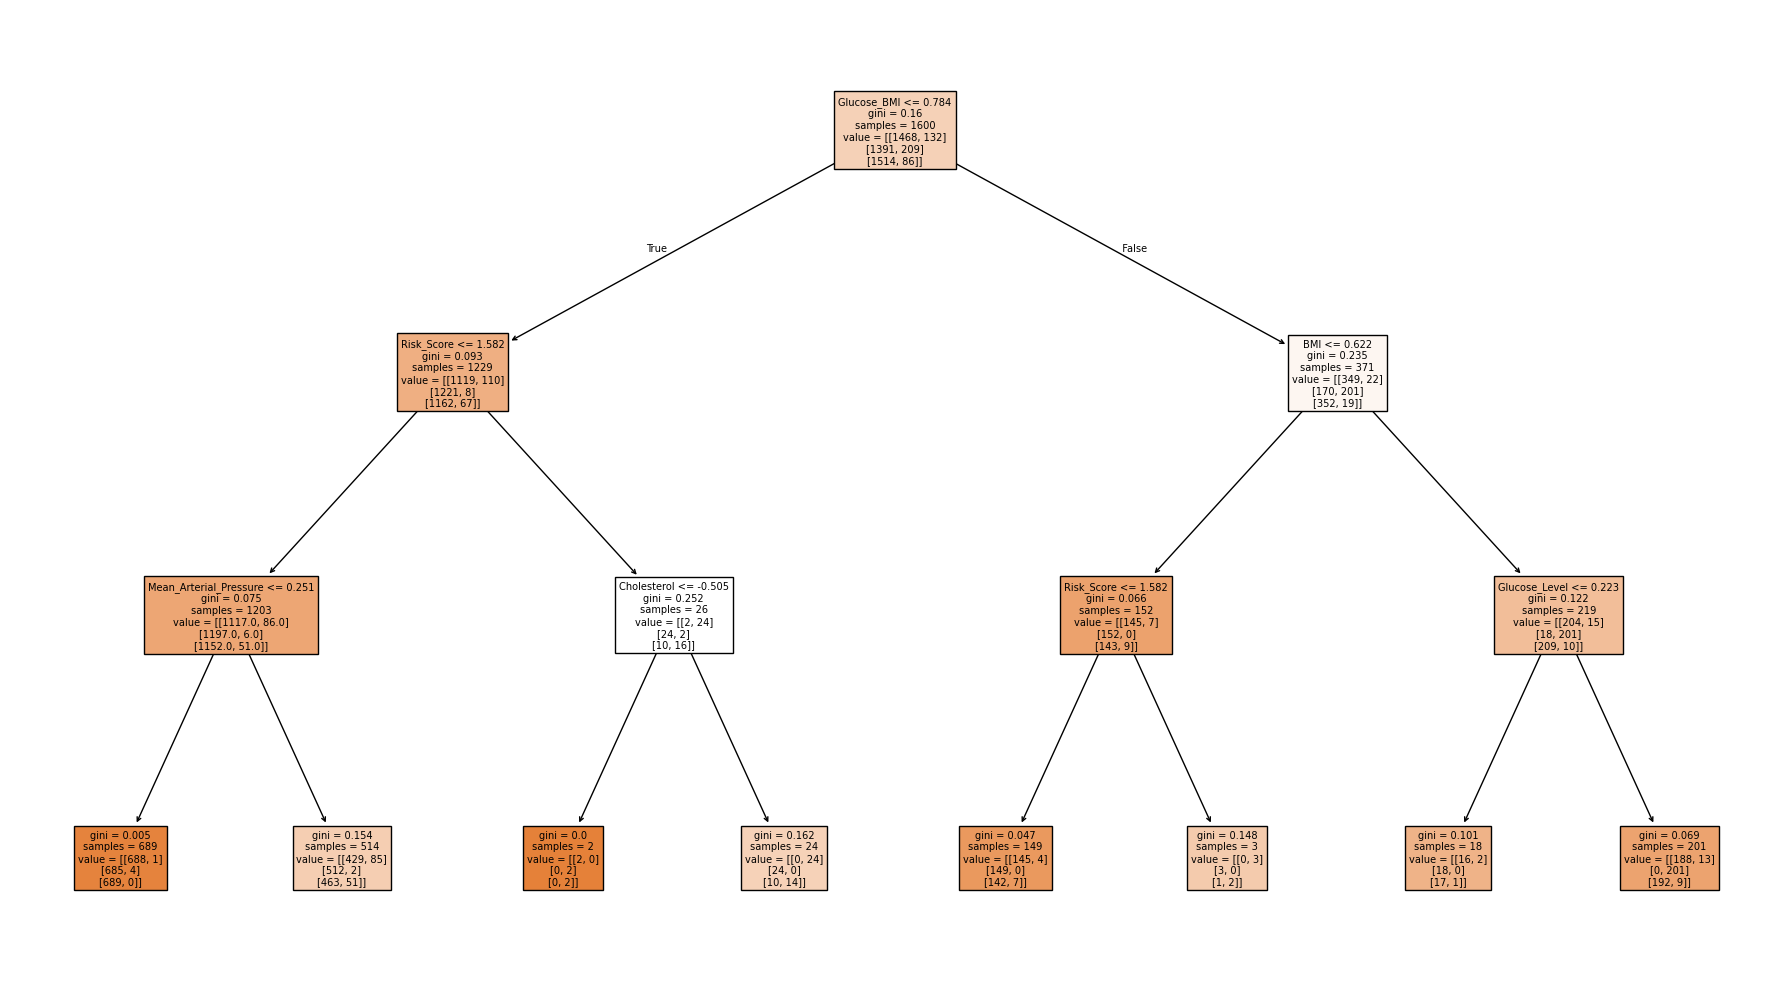

In [70]:
from sklearn.tree import plot_tree
plt.figure(figsize = (18,10))
plot_tree(
    model,
    feature_names = X.columns,
    class_names = ["Heart_Disease","Diabetes","Stroke"],
    filled = True
)
plt.tight_layout()
plt.show()



In [71]:
# Random_Forest_Classifier:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(max_depth = 4, random_state = 42)
model.fit(X_train_scaled,Y_train)
Y_predict = model.predict(X_test_scaled)
Y_predict
Y_test
# Evaluation:
from sklearn.metrics import accuracy_score,precision_score,f1_score,recall_score
print("Random_Forest_Classifier:")
print("accuracy_score:", accuracy_score(Y_test,Y_predict))


Random_Forest_Classifier:
accuracy_score: 0.915
